In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, peak_widths

ROOT = Path.cwd()
INPUT = ROOT / "asd_2d_results" / "asd_dynamical_structure_factor_T0p1.npz"
OUTPUT = ROOT / "asd_spectral_analysis"
OUTPUT.mkdir(parents=True, exist_ok=True)

with np.load(INPUT) as data:
    qx = data["qx"].copy()
    qy = data["qy"].copy()
    omega = data["omega"].copy()
    S_dmi = data["S_dmi"].astype(np.float64)
    S_fr = data["S_frustration"].astype(np.float64)
    T_asd = float(data["temperature"])
    replicas_asd = int(data["n_replicas"])
    e_dmi = data["energy_dmi"].copy()
    e_fr = data["energy_frustration"].copy()
    J = float(data["J"])
    D = float(data["D"])
    J2 = float(data["J2"])
    B_z = float(data["B_z"])

q0 = np.pi / 4
Delta_omega = omega[1] - omega[0]

assert S_dmi.shape == S_fr.shape == (len(omega), len(qx), len(qy))
assert abs(B_z) < 1e-12

print("Temperature:", T_asd)
print("Replicas:", replicas_asd)
print("Spectrum shape:", S_dmi.shape)
print("Frequency resolution:", Delta_omega)
print("Frequency Nyquist:", omega[-1])
print("Output:", OUTPUT)

Temperature: 0.1
Replicas: 4
Spectrum shape: (256, 64, 64)
Frequency resolution: 0.09817477042468103
Frequency Nyquist: 25.034566458293664
Output: /home/senji77/akhyar/research/notebooks/ANSW/asd_spectral_analysis


In [2]:
def lswt_frequency(kx, ky, model):
    cq = np.cos(q0)
    cx = np.cos(kx)
    cy = np.cos(ky)

    if model == "dmi":
        lam = 2 * J * (1 + cq) + 2 * D * np.sin(q0)
        A = lam - 2 * J * (cx + cy)
        B = lam - 2 * ((J * cq + D * np.sin(q0)) * cx + J * cy)
    else:
        lam = 2 * J * (1 + cq) - 2 * J2 * np.cos(2 * q0)
        A = lam - 2 * J * (cx + cy) + 2 * J2 * np.cos(2 * kx)
        B = lam - 2 * J * (cq * cx + cy) + 2 * J2 * np.cos(2 * q0) * np.cos(2 * kx)

    return np.sqrt(np.maximum(A * B, 0))


def lab_frame_candidates(kx, ky, model):
    return (
        lswt_frequency(kx, ky, model),
        lswt_frequency(kx - q0, ky, model),
        lswt_frequency(kx + q0, ky, model)
    )

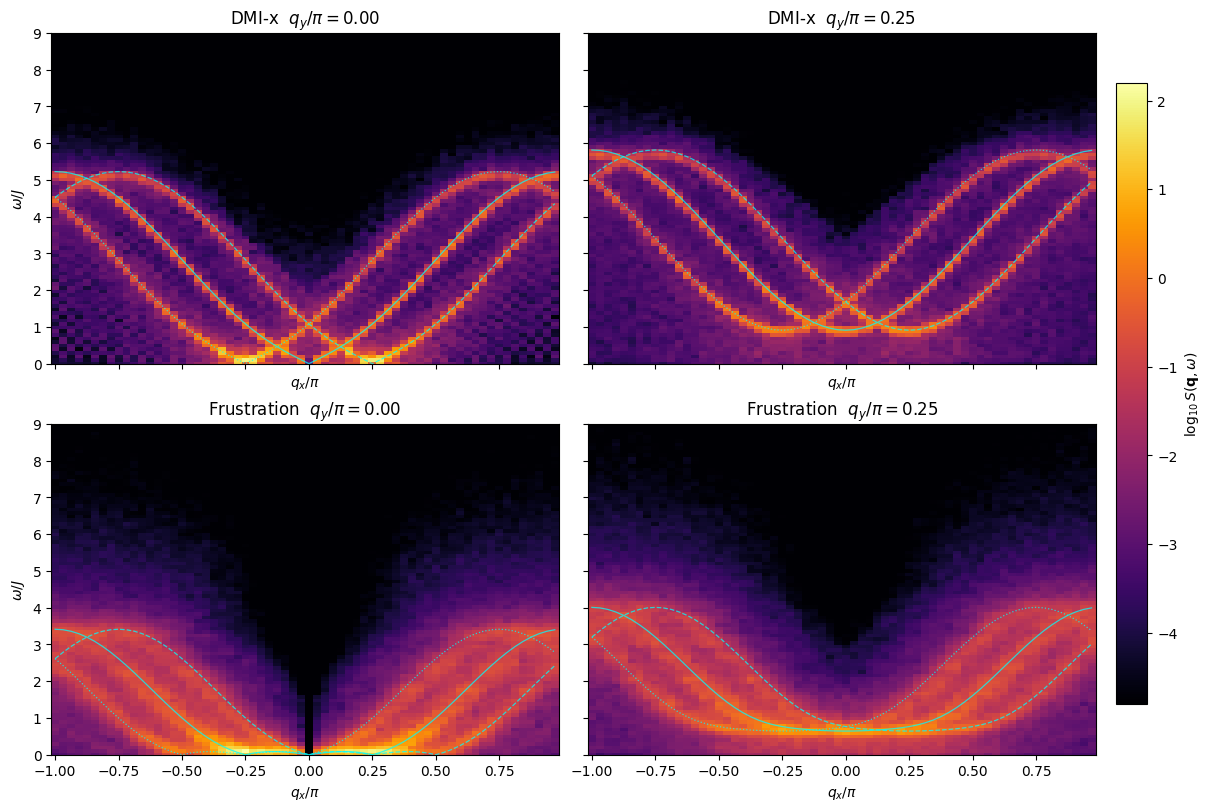

In [3]:
ky_targets = [0.0, np.pi / 4]
ky_indices = [np.argmin(np.abs(qy - k)) for k in ky_targets]
models = [("DMI-x", "dmi", S_dmi), ("Frustration", "frustration", S_fr)]

scale = max(np.max(S_dmi), np.max(S_fr))
floor = scale * 1e-7

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True, constrained_layout=True)

for row, (name, model, spectrum) in enumerate(models):
    for col, iy in enumerate(ky_indices):
        ax = axes[row, col]
        ky = qy[iy]
        im = ax.pcolormesh(
            qx / np.pi, omega,
            np.log10(np.maximum(spectrum[:, :, iy], floor)),
            cmap="inferno", vmin=np.log10(floor), vmax=np.log10(scale), shading="auto"
        )

        curves = lab_frame_candidates(qx, ky, model)
        for curve, style in zip(curves, ["-", "--", ":"]):
            ax.plot(qx / np.pi, curve, color="cyan", ls=style, lw=0.9, alpha=0.75)

        ax.set_title(rf"{name}  $q_y/\pi={ky/np.pi:.2f}$")
        ax.set_ylim(0, 9)
        ax.set_xlabel(r"$q_x/\pi$")
        if col == 0:
            ax.set_ylabel(r"$\omega/J$")

fig.colorbar(im, ax=axes, shrink=0.86, pad=0.02, label=r"$\log_{10} S(\mathbf{q},\omega)$")
fig.savefig(OUTPUT / "asd_lswt_labframe_overlay.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_lswt_labframe_overlay.png", dpi=350, bbox_inches="tight")
plt.show()

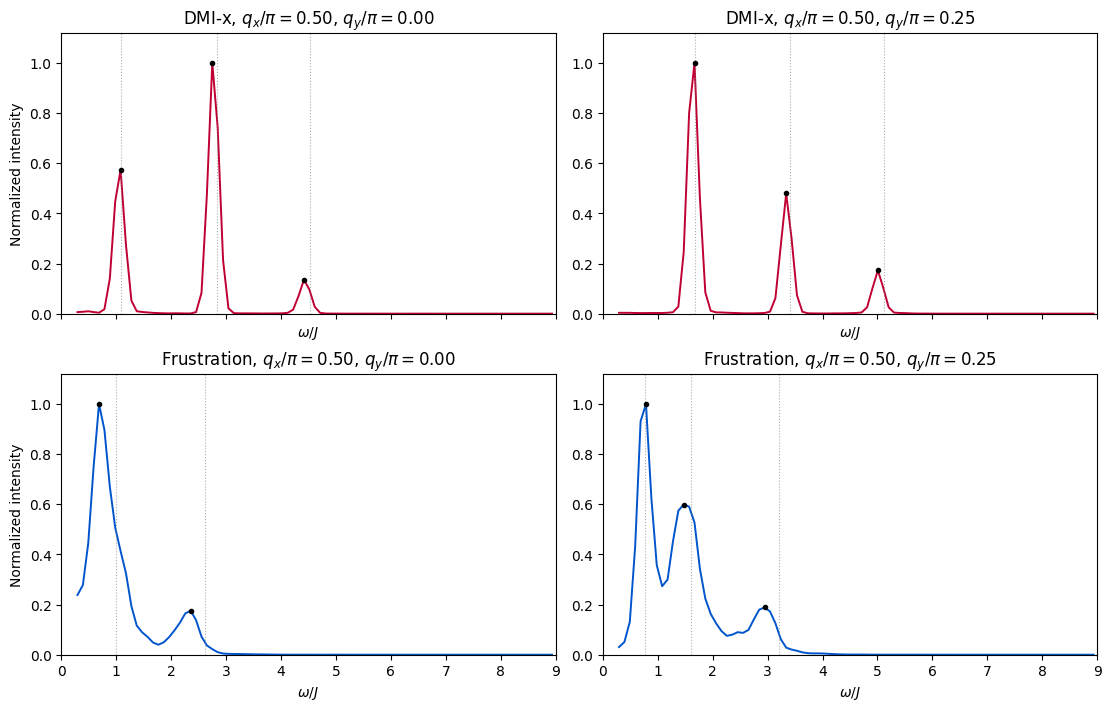

DMI-x        q/pi=(0.50,0.00)  omega=2.7489  width=0.2368  intensity=1.000
DMI-x        q/pi=(0.50,0.00)  omega=1.0799  width=0.2419  intensity=0.574
DMI-x        q/pi=(0.50,0.00)  omega=4.4179  width=0.2409  intensity=0.136
DMI-x        q/pi=(0.50,0.25)  omega=1.6690  width=0.2421  intensity=1.000
DMI-x        q/pi=(0.50,0.25)  omega=3.3379  width=0.2369  intensity=0.480
DMI-x        q/pi=(0.50,0.25)  omega=5.0069  width=0.2368  intensity=0.173
Frustration  q/pi=(0.50,0.00)  omega=0.6872  width=0.3679  intensity=1.000
Frustration  q/pi=(0.50,0.00)  omega=2.3562  width=0.4045  intensity=0.175
Frustration  q/pi=(0.50,0.25)  omega=0.7854  width=0.3185  intensity=1.000
Frustration  q/pi=(0.50,0.25)  omega=1.4726  width=0.4507  intensity=0.599
Frustration  q/pi=(0.50,0.25)  omega=2.9452  width=0.4002  intensity=0.189


In [4]:
qx_targets = [np.pi / 2, np.pi / 2]
ky_targets = [0.0, np.pi / 4]
peak_rows = []

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, constrained_layout=True)

for row, (name, model, spectrum) in enumerate(models):
    for col, (kx_target, ky_target) in enumerate(zip(qx_targets, ky_targets)):
        ix = np.argmin(np.abs(qx - kx_target))
        iy = np.argmin(np.abs(qy - ky_target))
        kx, ky = qx[ix], qy[iy]

        valid = (omega >= 0.25) & (omega <= 9.0)
        frequencies = omega[valid]
        profile = spectrum[valid, ix, iy]
        profile = gaussian_filter1d(profile, sigma=0.8)
        profile = profile / max(np.max(profile), 1e-30)

        indices, properties = find_peaks(profile, prominence=0.08, height=0.12, distance=3)
        if len(indices):
            widths = peak_widths(profile, indices, rel_height=0.5)[0] * Delta_omega
            chosen = np.argsort(profile[indices])[::-1][:4]
        else:
            widths = np.array([])
            chosen = []

        ax = axes[row, col]
        ax.plot(frequencies, profile, color="#C00032" if model == "dmi" else "#0055CC", lw=1.4)

        for theory in lab_frame_candidates(kx, ky, model):
            if 0.25 <= theory <= 9.0:
                ax.axvline(theory, color="gray", lw=0.8, ls=":", alpha=0.65)

        for position in chosen:
            p = indices[position]
            ax.plot(frequencies[p], profile[p], "ko", ms=3)
            peak_rows.append({
                "model": name,
                "qx": float(kx),
                "qy": float(ky),
                "omega_peak": float(frequencies[p]),
                "relative_height": float(profile[p]),
                "prominence": float(properties["prominences"][position]),
                "apparent_width": float(widths[position])
            })

        ax.set_title(rf"{name}, $q_x/\pi={kx/np.pi:.2f}$, $q_y/\pi={ky/np.pi:.2f}$")
        ax.set_xlim(0, 9)
        ax.set_ylim(0, 1.12)
        ax.set_xlabel(r"$\omega/J$")
        if col == 0:
            ax.set_ylabel("Normalized intensity")

fig.savefig(OUTPUT / "asd_peak_profiles.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_peak_profiles.png", dpi=350, bbox_inches="tight")
plt.show()

for row in peak_rows:
    print(f"{row['model']:12s} q/pi=({row['qx']/np.pi:.2f},{row['qy']/np.pi:.2f})  omega={row['omega_peak']:.4f}  width={row['apparent_width']:.4f}  intensity={row['relative_height']:.3f}")

DMI-x mean |intensity asymmetry| in high-signal pixels: 0.16799867377534275
Frustration mean |intensity asymmetry| in high-signal pixels: 0.07452017365570317


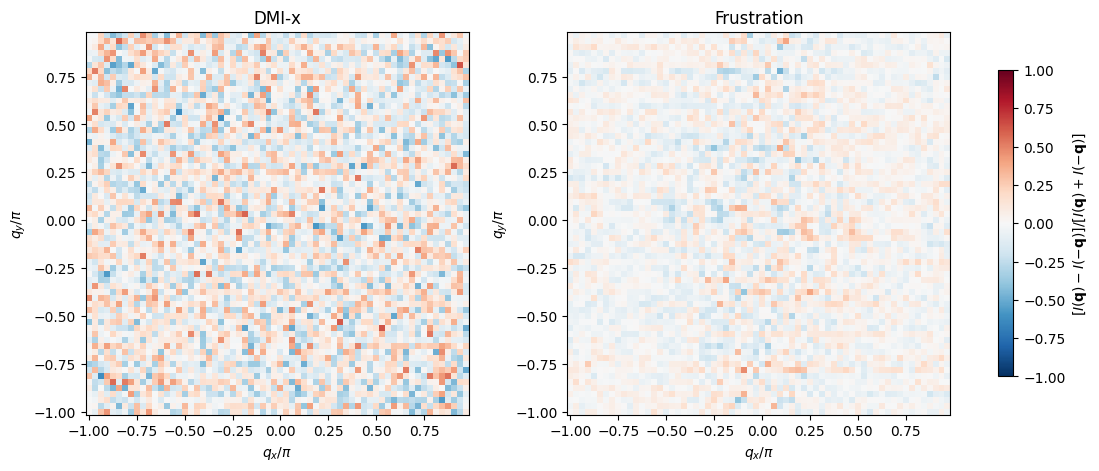

In [5]:
omega_window = (omega >= 0.3) & (omega <= 8.0)
neg_x = (-np.arange(len(qx))) % len(qx)
neg_y = (-np.arange(len(qy))) % len(qy)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
asymmetry = {}

for ax, (name, model, spectrum) in zip(axes, models):
    intensity = np.trapezoid(spectrum[omega_window], omega[omega_window], axis=0)
    reversed_intensity = intensity[np.ix_(neg_x, neg_y)]
    epsilon = np.max(intensity) * 1e-8
    A = (intensity - reversed_intensity) / (intensity + reversed_intensity + epsilon)
    asymmetry[model] = A

    im = ax.pcolormesh(
        qx / np.pi, qy / np.pi, A.T,
        cmap="RdBu_r", vmin=-1, vmax=1, shading="auto"
    )
    ax.set_title(name)
    ax.set_xlabel(r"$q_x/\pi$")
    ax.set_ylabel(r"$q_y/\pi$")
    ax.set_aspect("equal")

    mask = intensity > 0.02 * np.max(intensity)
    print(name, "mean |intensity asymmetry| in high-signal pixels:", np.mean(np.abs(A[mask])))

fig.colorbar(im, ax=axes, shrink=0.8, label=r"$[I(\mathbf{q})-I(-\mathbf{q})]/[I(\mathbf{q})+I(-\mathbf{q})]$")
fig.savefig(OUTPUT / "asd_integrated_intensity_asymmetry.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_integrated_intensity_asymmetry.png", dpi=350, bbox_inches="tight")
plt.show()

In [6]:
for name, energies in [("DMI-x", e_dmi), ("Frustration", e_fr)]:
    relative = np.abs(energies - energies[0]) / np.maximum(np.abs(energies[0]), 1e-10)
    print(name, "maximum recorded relative energy drift:", np.max(relative))

print("Frequency resolution:", Delta_omega)
print("Temperature:", T_asd)
print("Replicas:", replicas_asd)

columns = ["model", "qx", "qy", "omega_peak", "relative_height", "prominence", "apparent_width"]

with open(OUTPUT / "asd_peak_table.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(peak_rows)

np.savez_compressed(
    OUTPUT / "asd_analysis_summary.npz",
    qx=qx, qy=qy, omega=omega,
    A_dmi=asymmetry["dmi"],
    A_frustration=asymmetry["frustration"],
    temperature=T_asd,
    frequency_resolution=Delta_omega
)

print("Saved:", OUTPUT)

DMI-x maximum recorded relative energy drift: 2.2687437380160452e-05
Frustration maximum recorded relative energy drift: 6.676304969359698e-06
Frequency resolution: 0.09817477042468103
Temperature: 0.1
Replicas: 4
Saved: /home/senji77/akhyar/research/notebooks/ANSW/asd_spectral_analysis
